In [44]:
import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from safetensors.torch import load_file

# Add parent directory to path to import utils if needed
sys.path.append(str(Path.cwd().parent))

# Configuration
RESULTS_DIR = Path("../results/cocoqa_img_vs_txt/similarities")
PLOTS_DIR = Path("../plots/multimodality_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Pretrained": "llava-v1.5-7b-pretrained-lbasile",
    "Finetuned": "llava-1.5-7b-hf"
}

MEASURES = {
    "neighborhood_overlap": "Neighborhood Overlap",
    "linear_cka": "Linear CKA"
}

In [45]:
def load_data(model_name, measure_key):
    filename = f"{model_name}_{measure_key}.safetensors"
    path = RESULTS_DIR / filename
    try:
        data = load_file(str(path))
        # The key inside safetensors matches the measure name (e.g. "neighborhood_overlap")
        tensor = data[measure_key]
        return tensor.cpu().numpy()
    except Exception as e:
        print(f"Error loading {filename}: {e}")
        return None

def plot_measure_comparison(measure_key, measure_title):
    # Load data for both models
    data_pm = load_data(MODELS["Pretrained"], measure_key)
    data_fm = load_data(MODELS["Finetuned"], measure_key)

    if data_pm is None or data_fm is None:
        print(f"Skipping plot for {measure_title} due to missing data.")
        return

    # Setup figure with better spacing
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

    # Plot configuration
    models_list = [("Pretrained", data_pm), ("Finetuned", data_fm)]

    for idx, (model_label, data) in enumerate(models_list):
        ax = axes[idx]

        # Create heatmap with horizontal colorbar
        sns.heatmap(
            data,
            ax=ax,
            cmap="viridis",
            vmin=0, vmax=1,
            square=True,
            cbar=idx == 1,  # Only show colorbar on right subplot
            cbar_kws={
                "label": measure_title,
                "orientation": "horizontal",
                "shrink": 0.8,
                "aspect": 30,
                "pad": 0.08
            }
        )

        # Formatting with clean hierarchy
        ax.set_title(f"{model_label}", fontsize=18, pad=10, fontweight='medium')
        ax.set_xlabel("Image Layers", fontsize=13, labelpad=8)
        ax.set_ylabel("Text Layers", fontsize=13, labelpad=8)

        # Invert Y axis for intuitive layer ordering
        ax.invert_yaxis()

        # Optimized tick labels
        num_layers = data.shape[0]
        ticks = range(0, num_layers, 5)
        ax.set_xticks([t + 0.5 for t in ticks])
        ax.set_xticklabels(ticks, fontsize=11)
        ax.set_yticks([t + 0.5 for t in ticks])
        ax.set_yticklabels(ticks, fontsize=11)

    # Add suptitle with proper spacing
    fig.suptitle(f"{measure_title}: Text vs Image Modality Similarity",
                 fontsize=22, fontweight='bold', y=0.995)

    # Adjust layout to prevent overlaps
    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # Save with high quality
    save_path = PLOTS_DIR / f"multimodality_{measure_key}_comparison.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"Saved plot to {save_path}")
    plt.show()

Saved plot to ../plots/multimodality_similarity/multimodality_neighborhood_overlap_comparison.png


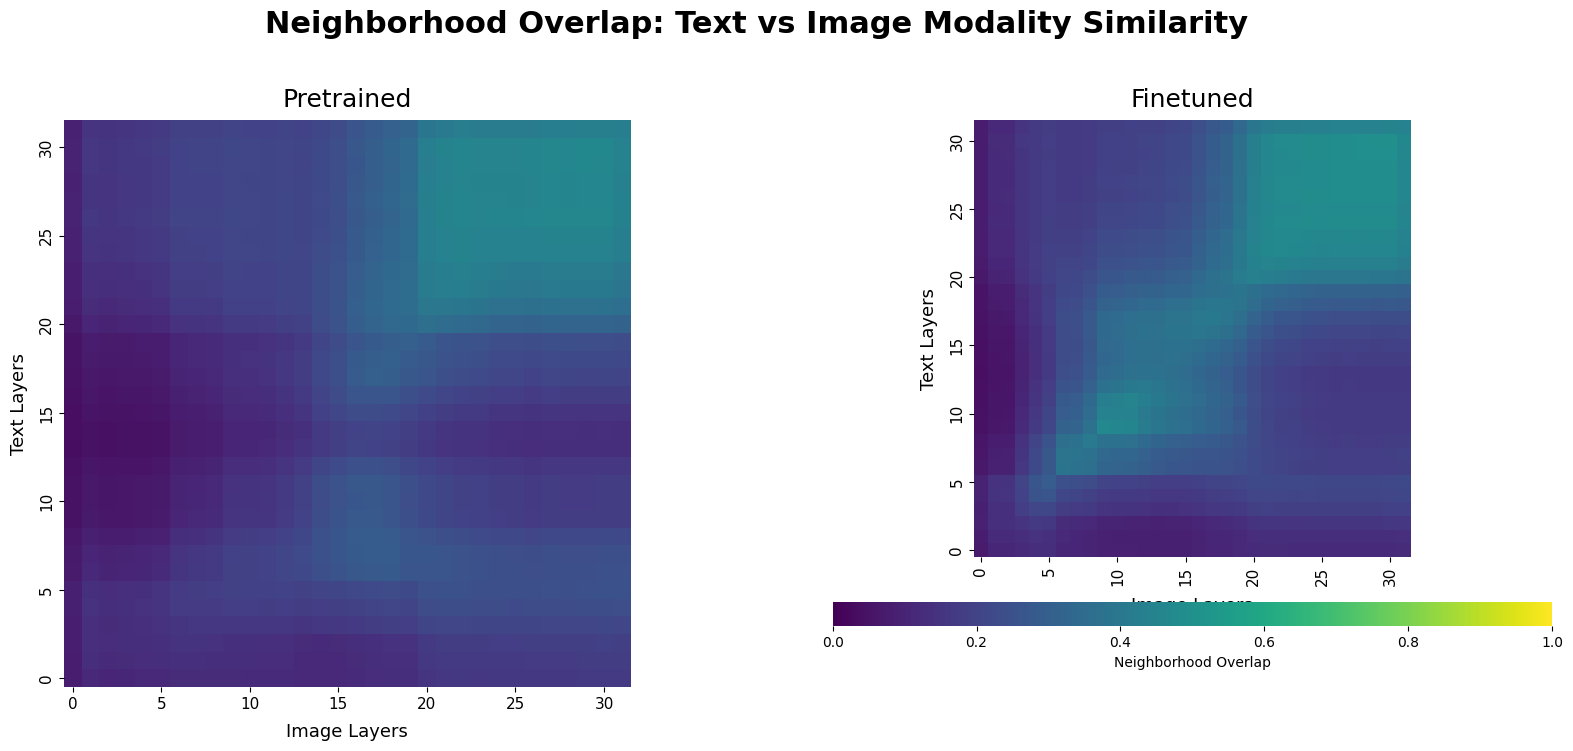

Saved plot to ../plots/multimodality_similarity/multimodality_linear_cka_comparison.png


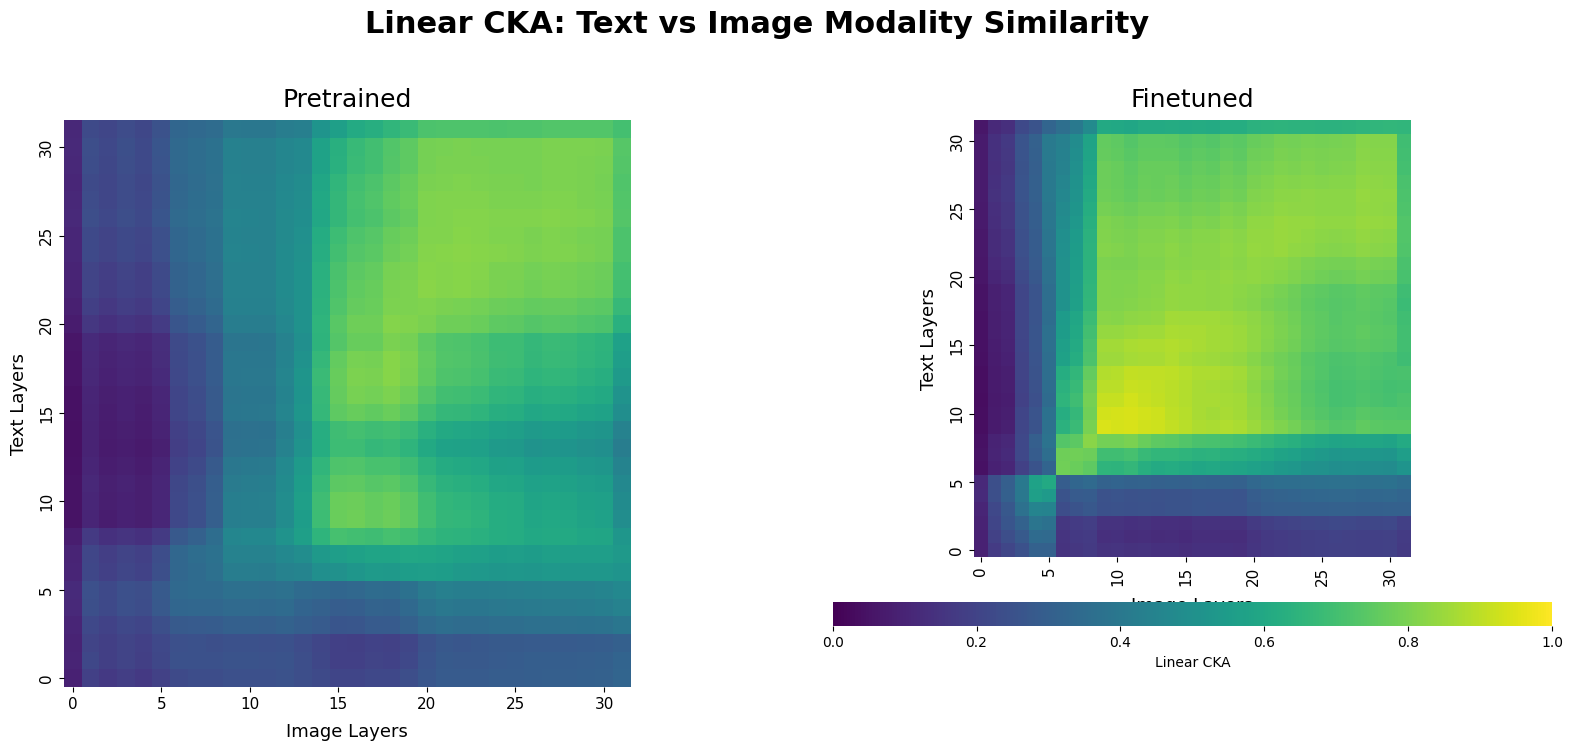

In [46]:
# Generate plots for all measures
for key, title in MEASURES.items():
    plot_measure_comparison(key, title)